KMeans: Customer Segmentation Data 用户分群

用 Customer Segmentation Data（用户分群数据集） 来练习 sklearn 中的 KMeans。这个项目属于无监督学习，目标是根据用户的消费行为，把用户自动划分成不同的群体。

特征：
- CustomerID,
- Gender,
- Age,
- Annual Income (k) 用户年收
- Spending Score (1-100) 用户消费评分，
- Annual Income (k)：


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

In [5]:
# 1. 加载用户分群 CSV 数据集
df = pd.read_csv("../../../data/ml/Mall_Customers.csv")

In [12]:
# 2. 查看数据
# df.info()
print("nan size: ", df.isnull().sum())
print("shape: ", df.shape)
print("dtype: ", df.dtypes)

print(df.columns.values)

nan size:  CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
shape:  (200, 5)
dtype:  CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object
<StringArray>
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
 'Spending Score (1-100)']
Length: 5, dtype: str


In [19]:
# 3. 选择聚类特征: 年收入'Annual Income (k$)' 消费评分'Spending Score (1-100)'
feature_columns = ['Annual Income (k$)', 'Spending Score (1-100)']
data = df.dropna(subset=feature_columns).copy()
data

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [24]:
# 4. 标准化特征
# - 计算每个特征的均值和标准差
# - 将特征转换到可比较的尺度
X_src = data[feature_columns]
X_train = X_src[:-20]
X_test = X_src[-20:]

scaler = StandardScaler()
scaler.fit(X_train)
X = scaler.transform(X_train)
X

# KMeans 是聚类算法，没有什么标签y了，所有的值都是特征


array([[-1.89968708, -0.43888179],
       [-1.89968708,  1.23684868],
       [-1.85231334, -1.75552715],
       [-1.85231334,  1.0772553 ],
       [-1.8049396 , -0.39898344],
       [-1.8049396 ,  1.03735695],
       [-1.75756585, -1.75552715],
       [-1.75756585,  1.75552715],
       [-1.71019211, -1.87522219],
       [-1.71019211,  0.87776358],
       [-1.71019211, -1.4363404 ],
       [-1.71019211,  1.95501888],
       [-1.66281837, -1.39644205],
       [-1.66281837,  1.0772553 ],
       [-1.66281837, -1.47623874],
       [-1.66281837,  1.15705199],
       [-1.61544463, -0.59847517],
       [-1.61544463,  0.63837351],
       [-1.52069714, -0.83786523],
       [-1.52069714,  1.91512053],
       [-1.4733234 , -0.59847517],
       [-1.4733234 ,  0.91766192],
       [-1.42594966, -1.7954255 ],
       [-1.42594966,  0.91766192],
       [-1.28382843, -1.4363404 ],
       [-1.28382843,  1.27674702],
       [-1.28382843, -0.7181702 ],
       [-1.28382843,  0.43888179],
       [-1.23645468,

In [33]:
#    5. 选择聚类数量 K
#     - 分别尝试 K = 2 到 K = 8
#     - 计算每个 K 对应的簇内平方和
#     - 计算每个 K 对应的轮廓系数
#     - 结合曲线和业务需求选择 K

# 对于 Kmeans 评估指标是 silhouette_score 越高越好

k_values = range(2, 9)
inertias = []
silhouette_scores = []
silhouette_scores_map = {}
for k in k_values:
    model = KMeans(n_clusters=k, random_state=23, n_init=10)
    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    silhouette_scores_map[k] = score
    print(
        f"K={k}, "
        f"Inertia={model.inertia_:.2f}, "
        f"Silhouette={silhouette_scores[-1]:.4f}"
    )

K=2, Inertia=228.25, Silhouette=0.3485
K=3, Inertia=155.54, Silhouette=0.4002
K=4, Inertia=102.46, Silhouette=0.4880
K=5, Inertia=46.95, Silhouette=0.5808
K=6, Inertia=36.08, Silhouette=0.5092
K=7, Inertia=31.22, Silhouette=0.4999
K=8, Inertia=27.39, Silhouette=0.4879


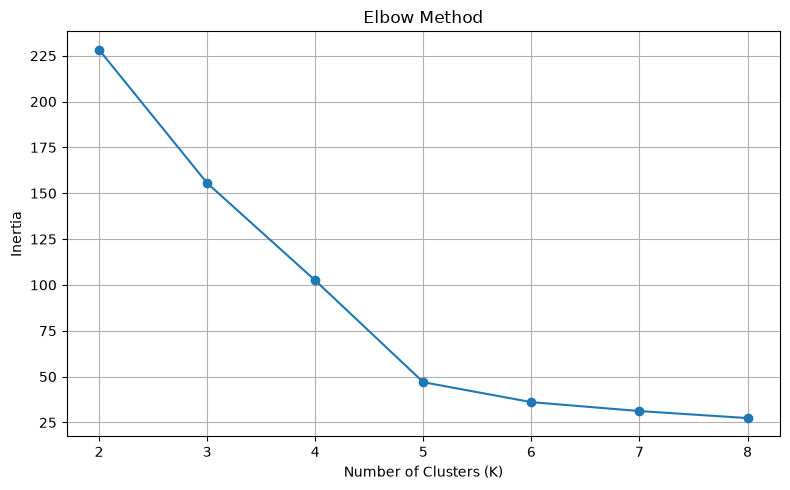

In [43]:
# 5. 绘制肘部法则曲线
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    inertias,
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

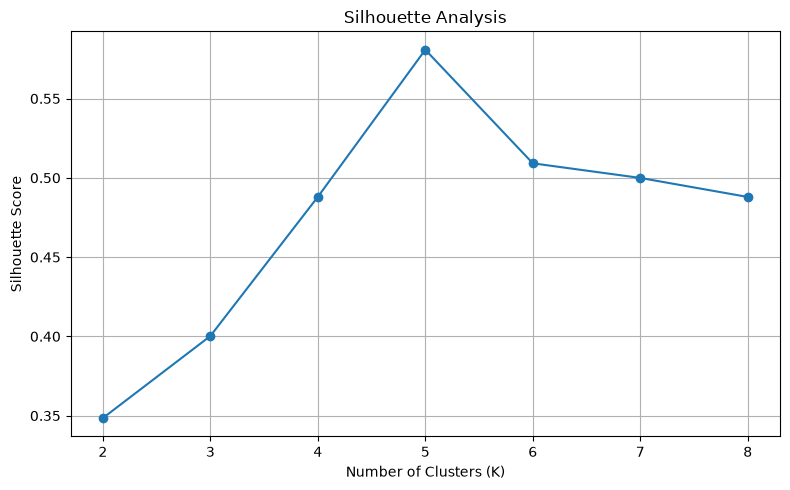

In [27]:
# 6. 绘制轮廓系数曲线
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

In [41]:

# 7. 训练最终模型
# 这里先采用经典练习中常见的 K=5
# 实际项目中应结合上面的曲线决定 K 值

best_k = max(
    silhouette_scores_map,
    key=silhouette_scores_map.get
)
print(best_k)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=23,
    n_init=10
)

data["Cluster"] = kmeans.fit_predict(X_scaled)

print("\n每个簇的用户数量：")
print(data["Cluster"].value_counts().sort_index())


5

每个簇的用户数量：
Cluster
0    81
1    35
2    39
3    23
4    22
Name: count, dtype: int64


In [29]:
# 8. 分析每个簇的特征
# 使用原始数值进行统计，更方便解释业务含义

profile = data.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Annual_Income=("Annual Income (k$)", "mean"),
    Avg_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("\n用户分群画像：")
print(profile)



用户分群画像：
         Customer_Count  Avg_Annual_Income  Avg_Spending_Score
Cluster                                                       
0                    81              55.30               49.52
1                    35              88.20               17.11
2                    39              86.54               82.13
3                    23              26.30               20.91
4                    22              25.73               79.36


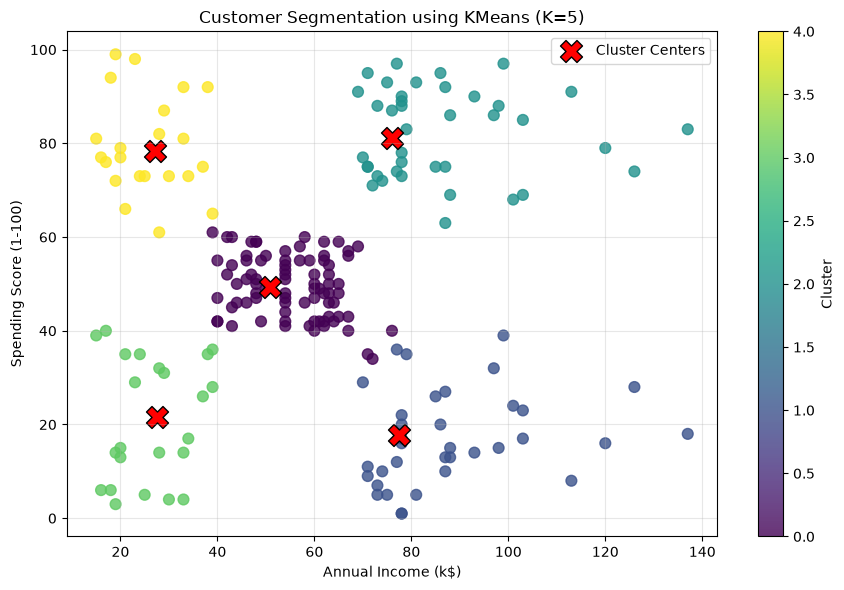

In [30]:
# 9. 绘制聚类结果
# 横轴：年收入
# 纵轴：消费评分
# 颜色：聚类标签

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    data["Annual Income (k$)"],
    data["Spending Score (1-100)"],
    c=data["Cluster"],
    cmap="viridis",
    s=60,
    alpha=0.8
)

# 将聚类中心从标准化尺度转换回原始尺度
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Cluster Centers"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"Customer Segmentation using KMeans (K={best_k})")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [31]:
# 10. 保存带聚类标签的数据
data.to_csv(
    "customer_segmentation_result.csv",
    index=False
)

print("\n聚类结果已保存到 customer_segmentation_result.csv")


聚类结果已保存到 customer_segmentation_result.csv
